## CMF-BO-GP 3.1

### Function 3 - Drug Discovery

You’re working on a drug discovery project, testing combinations of three compounds to create a new medicine. Each experiment is stored in initial_inputs.npy as a 3D array, where each row lists the amounts of the three compounds used.  After each experiment, you record the number of adverse reactions, stored in initial_outputs.npy as a 1D array. Your goal is to minimise side effects; in this competition, it is framed as maximisation by optimising a transformed output (e.g. the negative of side effects)


### Components to the model
#### 1. Import libraries
#### 2. Import and Analyse data - combining baseline data with new queries; then performing statistical analysis on the combined data
#### 3. Visualising data - create a 2D view with showing baseline, additional queries and current maxima - and a 3D representation.
#### 4. Core Model - v1 - UCB / EI models - with length scales and bounds
#### 5. Expliotation model - for final queries to maximise outputs (from scipy.optimize import minimize)

In [2]:
# ==============================================
# 1. Import required libraries to support model
# ==============================================

import numpy as np
import pandas as pd
from sklearn.feature_selection import mutual_info_regression
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from IPython.display import clear_output
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
from scipy.stats import norm
from scipy.interpolate import griddata

In [3]:
# ====================================
# 2. Import and Analyse the data set  
# ====================================

# Your 3D spatial coordinate data (10 positions)
inputs = np.load('/home/mcevoyj777/_CAPSTONE/Models/FUNC3/initial_inputs.npy')

# Your ouput values
output = np.load('/home/mcevoyj777/_CAPSTONE/Models/FUNC3/initial_outputs.npy')

print(f"Base Maximia: ",output.max())

extra_inputs = [[0.426738, 0.378192, 0.522188],	[0.486387, 0.000001, 0.642801],
                [0.813402, 1.000000, 0.850601],[1.000000, 1.000000, 0.476485],
                [0.371791, 0.261877, 0.364875],[0.287828, 0.824693, 0.520877],
                [0.000000, 0.658499, 0.450000],[0.908225, 0.070294, 0.345820],
                [0.000000, 0.500000, 0.500000],[1.000000, 0.654821, 0.440971],
                [0.418637, 0.787070, 0.422558],[0.418637, 0.787070, 0.422558]]
extra_output = [-0.01887344507525891,-0.17955537260329268,-0.0742921891442901,
                -0.048658772455942204,-0.07871334921778922,-0.04888117186184354,
               -0.015571889914751325,-0.11154457534377356,-0.029690975148155472,
               -0.01207823527894279,-0.01287661035865606,-0.039873941145402284]

inputs = np.vstack([inputs, extra_inputs])
output = np.append(output, extra_output)

print(f"Current Maxima: ",output.max())
print (len(output))

# Combine into a single Pandas DataFrame
df = pd.DataFrame(inputs, columns=['Input_X', 'Input_Y', 'Input_Z'])
df['Output_Target'] = output

# Compute the correlation matrix
# Change method to 'spearman' if relationships are non-linear curves
corr_matrix = df.corr(method='pearson')

# Isolate how each input correlates *only* with the target output
target_corr = corr_matrix['Output_Target'].drop('Output_Target')

print("Correlation with Output:")
print(target_corr)

# Calculate non-linear relationship dependency (higher score = stronger relationship)
mi_scores = mutual_info_regression(inputs, output)

for name, score in zip(['Input_X', 'Input_Y', 'Input_Z'], mi_scores):
    print(f"{name} Mutual Information Score: {score:.4f}")

# Fit a quick non-linear model that checks all 3 dimensions simultaneously
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(inputs, output)

# Extract total feature importances (including interactions)
importances = model.feature_importances_

for name, score in zip(['Input_X', 'Input_Y', 'Input_Z'], importances):
    print(f"{name} Total Importance (with interactions): {score:.4f}")

Base Maximia:  -0.034835313350078584
Current Maxima:  -0.01207823527894279
27
Correlation with Output:
Input_X    0.128254
Input_Y    0.322292
Input_Z   -0.409111
Name: Output_Target, dtype: float64
Input_X Mutual Information Score: 0.0082
Input_Y Mutual Information Score: 0.0544
Input_Z Mutual Information Score: 0.2350
Input_X Total Importance (with interactions): 0.0677
Input_Y Total Importance (with interactions): 0.2366
Input_Z Total Importance (with interactions): 0.6957


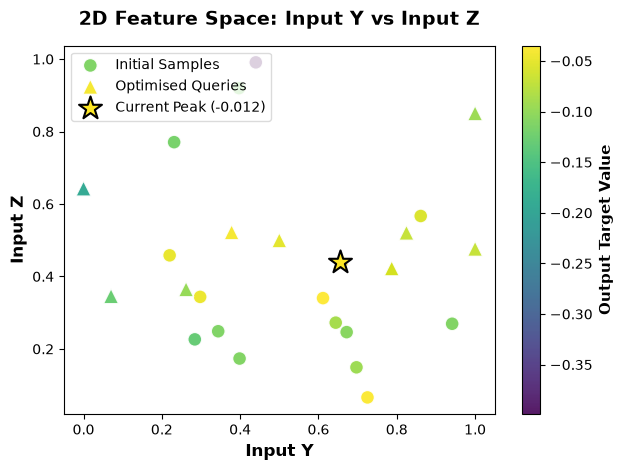

In [4]:
# ===================================
# 3.1 Visualise the data set Y and Z
# ===================================

# Find the coordinates of the maximum value dynamically
max_row_index = df['Output_Target'].idxmax()
max_y = df.loc[max_row_index, 'Input_Y']
max_z = df.loc[max_row_index, 'Input_Z']
max_val = df.loc[max_row_index, 'Output_Target']


# Create scatter plot with the first 15 smaples
scatter1 = plt.scatter(
    data=df.iloc[:15], 
    x='Input_Y', 
    y='Input_Z', 
    c='Output_Target', 
    cmap='viridis', 
    s=100,            # Marker size
    edgecolor='w',    # White border around markers
    alpha=0.9
)

# Plot the next query samples (e.g., as triangles '^')
scatter2 = plt.scatter(
    data=df.iloc[15:len(output)], 
    x='Input_Y', 
    y='Input_Z', 
    c='Output_Target', 
    cmap='viridis', 
    s=120,            # Made slightly larger so triangles stand out nicely
    edgecolor='w',    
    alpha=0.9,
    marker='^',       # <--- Shape for the next 9 points
    vmin=df['Output_Target'].min(),
    vmax=df['Output_Target'].max()
)

scatter3 = plt.scatter(
    x=max_y, 
    y=max_z, 
    c=[max_val],   
    cmap='viridis',    # Highly visible contrasting color
    vmin=df['Output_Target'].min(),
    vmax=df['Output_Target'].max(),
    s=300,            # Much larger marker size to make it pop
    marker='*',       # Star shape
    edgecolor='black',
    linewidth=1.5,
    label=f'Current Max ({max_val:.2f})',
    zorder=5          # Ensures it sits on top of all other points
)


# Add elements
cbar = plt.colorbar(scatter1)
cbar.set_label('Output Target Value', fontsize=11, fontweight='bold')
plt.xlabel('Input Y', fontsize=12, fontweight='bold')
plt.ylabel('Input Z', fontsize=12, fontweight='bold')
plt.title('2D Feature Space: Input Y vs Input Z', fontsize=14, fontweight='bold', pad=15)

plt.legend(
    handles=[scatter1, scatter2,scatter3], 
    labels=['Initial Samples', 'Optimised Queries', f'Current Peak ({max_val:.3f})'],
    loc='upper left', 
    frameon=True, 
    facecolor='white', 
    edgecolor='lightgray', 
    fontsize=10
)
plt.tight_layout()
plt.show()

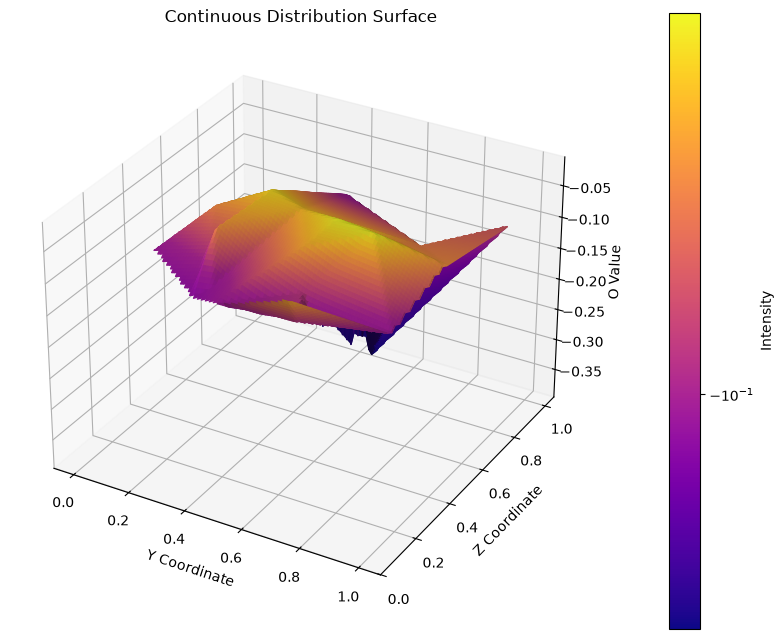

In [5]:
# ===================================
# 3.2. Visualise the data set 3D
# ===================================


coords = (inputs[:,1],inputs[:,2])

# Define a regular 2D grid based on your data boundaries
grid_x, grid_y = np.meshgrid(
    np.linspace(coords[0].min(), coords[0].max(), 100),
    np.linspace(coords[1].min(), coords[1].max(), 100)
)

# Interpolate the scattered (x, y, z) data onto the uniform grid
# Options for method: 'linear', 'cubic', or 'nearest'
grid_z = griddata((coords[0], coords[1]), output, (grid_x, grid_y), method='linear')

# If your y_clean variable is different from values, interpolate it too for the colors
grid_color = griddata((coords[0], coords[1]), output, (grid_x, grid_y), method='linear')

# Create the 3D surface plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
norm = colors.SymLogNorm(linthresh=0.1, vmin=output.min(), vmax=output.max())


# Plot the continuous surface
# facecolors overrides standard mapping to use your output
surf = ax.plot_surface(
    grid_x, grid_y, grid_z,
    facecolors=plt.cm.plasma(norm(grid_color)),
    rcount=100, ccount=100,  # Grid resolution
    antialiased=True,
    shade=True
)

# Design elements
# Create a dummy scalar mappable object just to display the colorbar correctly
mappable = plt.cm.ScalarMappable(cmap='plasma', norm=norm)
fig.colorbar(mappable, ax=ax, label="Intensity", pad=0.1)

ax.set_xlabel("Y Coordinate")
ax.set_ylabel("Z Coordinate")
ax.set_zlabel("O Value")
ax.set_title("Continuous Distribution Surface")

plt.show()

In [ ]:
# ====================================================
# 3.3. Visualise the data set along  dominant feature
# ====================================================


import matplotlib.pyplot as plt
import numpy as np

# 1. Create mock data (scattered data points)
x = df['Input_Z'].to_numpy() 
y = df['Output_Target'].to_numpy()  

# 2. Calculate the estimated curve line
# '2' means a degree-2 polynomial curve (quadratic: y = ax² + bx + c)
coefficients = np.polyfit(x, y, 4
                          
                         )
polynomial = np.poly1d(coefficients)

# 3. Create a smooth line range for drawing the curve smoothly
x_smooth = np.linspace(x.min(), x.max(), 200)
y_estimated = polynomial(x_smooth)

# 4. Generate the 2D plot
plt.figure(figsize=(8, 5))
plt.scatter(x, y, color='red', label='Raw Data Points', zorder=1)
plt.plot(x_smooth, y_estimated, color='blue', label='Estimated Curve', linewidth=2)

# 5. Customise and display the graph
plt.title('2D Line Graph with Estimated Curve Fit')
plt.xlabel('X Axis (Z Input)')
plt.ylabel('Y Axis (Ouptut)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [ ]:
# ===========================================
# 4 (v1) GP Model - with UCB/EI 
# ===========================================

predictor = RandomForestRegressor(n_estimators=100, random_state=42)
predictor.fit(inputs, output)

def objective_3d(X):
    # Force input to be 2D array matrix for sklearn compatibility
    X = np.atleast_2d(X)
    
    # Predict the output value using the trained model
    predictions = predictor.predict(X)
    
    # Return as a flat 1D array as expected by your code (.ravel())
    print(f"Prediction {predictions}")
    return predictions.ravel()

In [7]:
# Acquisition Functions #

import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, Matern
from scipy.stats import norm
from scipy.optimize import minimize
import warnings

warnings.filterwarnings('ignore')

def upper_confidence_bound(mu, sigma, kappa=0.1):
    """
    Upper Confidence Bound (UCB) acquisition function.
    
    UCB = mean + kappa * std
    
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation
    kappa : exploration parameter (higher = more exploration)
    """
    return mu + kappa * sigma


def expected_improvement(mu, sigma, y_best, xi=0.1):
    """
    Expected Improvement (EI) acquisition function.
    
    EI = E[max(f(x) - f(x_best), 0)]
    
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation  
    y_best : best observed value so far
    xi : exploration parameter
    """
    with np.errstate(divide='warn'):
        improvement = mu - y_best - xi
        Z = improvement / sigma
        ei = improvement * norm.cdf(Z) + sigma * norm.pdf(Z)
        ei[sigma == 0.0] = 0.0
    return ei

In [9]:
def bayesian_optimization_nd(objective_func, n_dims, n_iterations=1, 
                            n_initial=len(output), acquisition='ei'):
    """
    Bayesian Optimization for n-dimensional functions.
    Assumes bounds [0, 1] for all dimensions.
    """
    bounds = [(0, 1) for _ in range(n_dims)]
    
    # Initialize
    X_samples = inputs
    y_samples = output
    
    
    best_values = [y_samples.max()]
    
    print(f"Starting {n_dims}D optimization with {n_initial} initial samples...")
    print(f"Initial best: {y_samples.max():.4f}\n")

    
    # Initialize length scales: large for X and Y (ignores them), small/sensitive for Z
    # A large lengthscale tells the GP that moving along that axis changes nothing.
    init_length_scales = [0.5, 0.5, 0.05] 
        
    # Set bounds for the GP lengthscale optimizer
    # Crucial: Allow X and Y scales to grow massive, but let Z stay tight/sensitive
    length_scale_bounds = [
            (0.1, 100.0),   # Input_X bounds (ignore)
            (0.1, 100.0),   # Input_Y bounds (ignore)
            (0.1, 0.5)  # Input_Z bounds (forces focus here)
        ] 

    
    for iteration in range(n_iterations):
        # Fit GP
        kernel = ConstantKernel(1.0) * RBF(
            length_scale=init_length_scales, 
            length_scale_bounds=length_scale_bounds
        )
        gp = GaussianProcessRegressor(kernel=kernel, alpha=1e-6,normalize_y=True,
                                     n_restarts_optimizer=15)
        gp.fit(X_samples, y_samples)

        # Optimize acquisition function
        def acq_objective(X):
            X = X.reshape(1, -1)
            mu, sigma = gp.predict(X, return_std=True)
            
            if acquisition == 'ei':
                acq_val = expected_improvement(mu, sigma, y_samples.max())
            else:
                acq_val = upper_confidence_bound(mu, sigma, kappa=1.0)
           
            return -acq_val
        
        # Multi-start optimization
        best_acq = np.inf
        X_next = None

        # Build dynamic, localized acquisition optimization bounds
        # X and Y remain free (0, 1). Z is focused tightly around the 0.52 peak zone.
        localized_bounds = [
            (0.0, 1.0),  # Input_X free global search
            (0.2, 1.0),  # Input_Y free global search
            (0.4, 1.0),  # Input_Z restricted hill-climbing window
        ]

        
        for _ in range(20):  # More starts for higher dimensions
            # Sample initial multi-start points respecting the localized constraints
            x0 = np.array(
                [
                    np.random.uniform(localized_bounds[0][0], bounds[0][1]),
                    np.random.uniform(localized_bounds[1][0], bounds[1][1]),
                    np.random.uniform(localized_bounds[2][0], bounds[2][1]),
                ]
            )
            result = minimize(acq_objective, x0, bounds=localized_bounds, method='L-BFGS-B',options={"ftol": 1e-9},)
            if result.fun < best_acq:
                best_acq = result.fun
                X_next = result.x
                print(f"Optimized Next Point Found! Predicted Acquisition Score: {-best_acq:.6f}")
                print(f"Coordinates to test next: {X_next}")

       
        # Evaluate
        y_next = objective_func(X_next.reshape(1, -1)).ravel()
        
        # Update
        X_samples = np.vstack([X_samples, X_next])
        y_samples = np.append(y_samples, y_next)
        best_values.append(y_samples.max())
        
        if (iteration + 1) % 10 == 0:
            print(f"Iteration {iteration + 1}: Best f(x)={y_samples.max():.4f}")
    
    return X_samples, y_samples, best_values



# Run 3D optimization
X_samples_3d, y_samples_3d, best_values_3d = bayesian_optimization_nd(
    objective_3d, 
    n_dims=3,
    n_iterations=3,
    acquisition='ei'
)

Starting 3D optimization with 27 initial samples...
Initial best: -0.0121

Optimized Next Point Found! Predicted Acquisition Score: 0.000000
Coordinates to test next: [0.35310037 0.37637683 0.54270776]
Optimized Next Point Found! Predicted Acquisition Score: 0.002466
Coordinates to test next: [1.        0.2       0.8418926]
Prediction [-0.11217682]
Optimized Next Point Found! Predicted Acquisition Score: 0.000333
Coordinates to test next: [0.         1.         0.70619457]
Prediction [-0.07893569]
Optimized Next Point Found! Predicted Acquisition Score: 0.000000
Coordinates to test next: [0.69980755 0.5926254  0.62649454]
Optimized Next Point Found! Predicted Acquisition Score: 0.000000
Coordinates to test next: [0.68480278 0.83459218 0.93930738]
Optimized Next Point Found! Predicted Acquisition Score: 0.000001
Coordinates to test next: [0.50354293 0.70074514 0.70888392]
Optimized Next Point Found! Predicted Acquisition Score: 0.000095
Coordinates to test next: [1.         1.         0

In [15]:
# ============================================
# 5. Exploitation Model - scipy.optimize
# ============================================

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel as C
from scipy.optimize import minimize

# 1. Load the 3D dataset (Features: X, Y, Z)
X_train = inputs
y_train = output

# 2. Configure a Matern GP Surrogate Model
# Matern nu=1.5 allows for the distinct "cliffs"
kernel = C(1.0, (1e-3, 1e3)) * Matern(length_scale=np.ones(3), length_scale_bounds=(1e-2, 10.0), nu=1.5)
gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=25, alpha=1e-6, random_state=42)

# Fit model to historical space
gp.fit(X_train, y_train)

# 3. Formulate Optimization Target (Negative prediction for minimization algorithm)
def objective(x):
    # Predict returns shape (1, 3), flatten to extract scalar
    return -float(gp.predict(x.reshape(1, -1))[0])

# 4. Enforce Bounding Box System limits [0.0, 1.0]
bounds = [
    (0.40, 1.0),  # X
    (0.10, 1.0),  # Y
    (0.30, 0.6)   # Z
]

# Use your historical peak coordinate as the optimization warm-start point
x_start = np.array([0.418637, 0.787070, 0.422558])

# 5. Execute L-BFGS-B Optimization Local Search
result = minimize(objective, x_start, method='L-BFGS-B', bounds=bounds)

# 6. Display Predicted Coordinates
print("--- GAUSSIAN PROCESS TARGET PREDICTION ---")
print(f"Predicted Max Output: {abs(result.fun):.4f}")
print("Optimal Coordinates:")
for name, val in zip(['X', 'Y', 'Z'], result.x):
    print(f"  Input_{name}: {val:.6f}")


--- GAUSSIAN PROCESS TARGET PREDICTION ---
Predicted Max Output: 0.0107
Optimal Coordinates:
  Input_X: 0.980938
  Input_Y: 0.652749
  Input_Z: 0.448306
